# WordCount : Python simple vs pseudo-MapReduce vs Hadoop MapReduce

**Objectif** : compter le nombre d'occurrences de chaque mot d'un fichier avec trois approches (codes repris du rapport *ComptageMots.pdf*), puis les comparer selon trois axes :

| Axe | Question posée |
|---|---|
| **Structure** | Comment le traitement est-il découpé ? |
| **Outils** | Quelles technologies sont mobilisées ? |
| **Temps d'exécution** | Comment évolue la durée quand le volume augmente ? |

**Plan**
0. Données : les fichiers `data/mots_N.txt`, `data/mots_10N.txt`, `data/mots_100N.txt`, `data/mots_1000N.txt` et `data/mots_10000N.txt` (un mot par ligne)
1. Version 1 : Python simple
2. Version 2 : pseudo-MapReduce en Python (mapper → shuffle → reducer)
3. Version 3 : Hadoop MapReduce (HDFS + YARN, job `wordcount` officiel)
4. Comparaison et analyse

**Partie 2 — PySpark**

5. Le problème et présentation de PySpark
6. Mise en place de Spark
7. Le code expliqué (RDD puis DataFrame)
8. Tests
9. Mesures : temps, parallélisme, cache en mémoire
10. Comparaison avec la partie 1
11. Conclusion : ce qu'apporte PySpark

## 0. Données

On utilise cinq fichiers du dossier `data/`, contenant **un mot par ligne** :

| Fichier | Taille |
|---|---|
| `mots_N.txt` | N lignes |
| `mots_10N.txt` | 10·N lignes |
| `mots_100N.txt` | 100·N lignes |
| `mots_1000N.txt` | 1000·N lignes — créé ci-dessous en dupliquant `mots_N.txt` |
| `mots_10000N.txt` | 10000·N lignes — créé ci-dessous en dupliquant `mots_N.txt` |

Un temps isolé ne dit pas grand-chose : ce qui compte, c'est **comment il évolue avec le volume**.

### Création de `mots_1000N.txt` par duplication

On recopie 1 000 fois le contenu de `mots_N.txt` à la suite dans un nouveau fichier. Si le fichier existe déjà, on ne fait rien : on peut donc relancer la cellule sans le recréer.

In [5]:
from pathlib import Path

source = Path("data/mots_N.txt")
copie = Path("data/mots_1000N.txt")
NB_COPIES = 1000

if copie.exists():
    print(f"{copie} existe déjà : rien à faire")
else:
    contenu = source.read_text(encoding="utf-8")
    if not contenu.endswith("\n"):      # sinon le dernier mot d'une copie se colle au premier de la suivante
        contenu += "\n"
    with open(copie, "w", encoding="utf-8") as f:
        for _ in range(NB_COPIES):
            f.write(contenu)
    print(f"{copie} créé : {NB_COPIES} copies de {source}")

data/mots_1000N.txt existe déjà : rien à faire


### Création de `mots_10000N.txt` par duplication

Même principe, avec 10 000 copies de `mots_N.txt` (10 millions de lignes, environ 61 Mo). Si le fichier existe déjà, on ne fait rien.

In [6]:
source = Path("data/mots_N.txt")
copie = Path("data/mots_10000N.txt")
NB_COPIES = 10000

if copie.exists():
    print(f"{copie} existe déjà : rien à faire")
else:
    contenu = source.read_text(encoding="utf-8")
    if not contenu.endswith("\n"):      # sinon le dernier mot d'une copie se colle au premier de la suivante
        contenu += "\n"
    with open(copie, "w", encoding="utf-8") as f:
        for _ in range(NB_COPIES):
            f.write(contenu)
    print(f"{copie} créé : {NB_COPIES} copies de {source}")

data/mots_10000N.txt existe déjà : rien à faire


In [7]:
import os, sys, time, importlib
from pathlib import Path

DATA_DIR = Path("data")
CORPUS = {nom: DATA_DIR / f"mots_{nom}.txt" for nom in ["N", "10N", "100N", "1000N", "10000N"]}

LIGNES = {}
for nom, p in CORPUS.items():
    assert p.exists(), f"Fichier manquant : {p}"
    with open(p, encoding="utf-8") as f:
        LIGNES[nom] = sum(1 for _ in f)
    print(f"{p.name:15s} : {LIGNES[nom]:>10,d} lignes | {p.stat().st_size / 1e6:7.2f} Mo")

mots_N.txt      :      1,000 lignes |    0.01 Mo
mots_10N.txt    :     10,000 lignes |    0.06 Mo
mots_100N.txt   :    100,000 lignes |    0.61 Mo
mots_1000N.txt  :  1,000,000 lignes |    6.10 Mo
mots_10000N.txt : 10,000,000 lignes |   60.98 Mo


**Règle d'équité** : les trois versions découpent le texte de la même façon, avec `split()` (séparation sur les espaces et retours à la ligne, comme dans le rapport). Avec un mot par ligne, une ligne = un mot.

On mémorise les temps mesurés dans `RESULTATS` au fur et à mesure.

## 1. Version 1 — Python simple

**Principe** : on lit tout le fichier, on le découpe en mots, et on incrémente un compteur dans un **dictionnaire** (`mot -> nombre`).

- **Structure** : une seule boucle, un seul processus, une seule machine.
- **Mémoire** : le fichier entier (`f.read()`) + le dictionnaire final.
- **Limite** : tout dépend de la puissance d'**une** machine ; si le fichier fait 10 To, ça ne passe plus.

On enregistre le code tel quel dans `wordcount.py`, puis on l'exécute comme dans le rapport (`time python wordcount.py`).

In [8]:
%%writefile wordcount.py
import sys

def compter_occurrences(fichier):
    with open(fichier, 'r', encoding='utf-8') as f:
        mots = f.read().split()

    compteur = {}
    for mot in mots:
        compteur[mot] = compteur.get(mot, 0) + 1
    return compteur

if __name__ == "__main__":
    fichier = sys.argv[1] if len(sys.argv) > 1 else "data/mots_N.txt"
    resultats = compter_occurrences(fichier)
    for mot, nb in sorted(resultats.items(), key=lambda x: x[1], reverse=True):
        print(f"{mot} : {nb}")

Overwriting wordcount.py


In [9]:
# Exécution du script comme dans le rapport (fichier de N lignes)
!time "{sys.executable}" wordcount.py data/mots_N.txt

chat : 120
chien : 100
fleur : 80
arbre : 80
maison : 70
soleil : 60
montagne : 60
livre : 50
ciel : 50
route : 40
mer : 40
lune : 40
eau : 35
oiseau : 30
voiture : 30
jardin : 30
pain : 20
table : 20
verre : 15
bouteille : 12
café : 10
porte : 8
"/Users/batistaureille/Desktop/Big Data/.venv/bin/python" wordcount.py   0.01s user 0.00s system 79% cpu 0.013 total


In [10]:
# Mesure du temps sur les 5 fichiers (fonction importée depuis wordcount.py)
import wordcount; importlib.reload(wordcount)

RESULTATS = []   # (version, corpus, temps en s)
res_v1 = {}
for nom, path in CORPUS.items():
    t0 = time.perf_counter()
    res_v1[nom] = wordcount.compter_occurrences(path)
    dt = time.perf_counter() - t0
    RESULTATS.append(("1. Python simple", nom, dt))
    print(f"{nom:6s} : {dt:8.4f} s | {len(res_v1[nom])} mots distincts")

print("\nbouteille :", {n: r.get("bouteille", 0) for n, r in res_v1.items()})

N      :   0.0001 s | 22 mots distincts
10N    :   0.0009 s | 22 mots distincts
100N   :   0.0081 s | 22 mots distincts
1000N  :   0.0703 s | 22 mots distincts
10000N :   0.6550 s | 22 mots distincts

bouteille : {'N': 12, '10N': 120, '100N': 1200, '1000N': 12000, '10000N': 120000}


## 2. Version 2 — pseudo-MapReduce en Python

On reproduit **à la main** les étapes de Hadoop, toujours sur une seule machine (code du rapport, *Listing 3*) :

1. **Map** (`mapper`) : chaque ligne est transformée en paires `(mot, 1)`.
2. **Shuffle** (`shuffle`) : on regroupe toutes les valeurs d'une même clé → `(mot, [1, 1, 1…])`.
3. **Reduce** (`reducer`) : on somme les valeurs de chaque clé → `(mot, total)`.

Intérêt pédagogique : voir le **modèle de programmation** sans l'infrastructure. Chaque appel à `mapper` est indépendant des autres → c'est ce qui le rend **parallélisable** sur un cluster.

In [11]:
%%writefile mapreduce_wordcount.py
import sys
from collections import defaultdict

def mapper(ligne):
    mots = ligne.strip().split()
    return [(mot, 1) for mot in mots]

def shuffle(mapped_data):
    grouped = defaultdict(list)
    for mot, valeur in mapped_data:
        grouped[mot].append(valeur)
    return grouped

def reducer(grouped_data):
    reduced = {}
    for mot, valeurs in grouped_data.items():
        reduced[mot] = sum(valeurs)
    return reduced

if __name__ == "__main__":
    fichier = sys.argv[1] if len(sys.argv) > 1 else "data/mots_N.txt"
    mapped = []
    with open(fichier, "r", encoding="utf-8") as f:
        for ligne in f:
            mapped.extend(mapper(ligne))

    grouped = shuffle(mapped)
    reduced = reducer(grouped)

    for mot, count in sorted(reduced.items(), key=lambda x: x[1], reverse=True):
        print(f"{mot} : {count}")

Overwriting mapreduce_wordcount.py


In [12]:
!time "{sys.executable}" mapreduce_wordcount.py data/mots_N.txt

chat : 120
chien : 100
fleur : 80
arbre : 80
maison : 70
soleil : 60
montagne : 60
livre : 50
ciel : 50
route : 40
mer : 40
lune : 40
eau : 35
oiseau : 30
voiture : 30
jardin : 30
pain : 20
table : 20
verre : 15
bouteille : 12
café : 10
porte : 8
"/Users/batistaureille/Desktop/Big Data/.venv/bin/python"  data/mots_N.txt  0.01s user 0.00s system 76% cpu 0.014 total


In [13]:
# Même enchaînement que le __main__ du script, en chronométrant chaque phase
import mapreduce_wordcount as mr; importlib.reload(mr)

res_v2, PHASES_V2 = {}, []
for nom, path in CORPUS.items():
    t = {}
    t0 = time.perf_counter()
    mapped = []
    with open(path, "r", encoding="utf-8") as f:
        for ligne in f:
            mapped.extend(mr.mapper(ligne))
    t["map"] = time.perf_counter() - t0
    t0 = time.perf_counter(); grouped = mr.shuffle(mapped);   t["shuffle"] = time.perf_counter() - t0
    t0 = time.perf_counter(); res_v2[nom] = mr.reducer(grouped); t["reduce"] = time.perf_counter() - t0
    total = sum(t.values())
    RESULTATS.append(("2. Pseudo-MapReduce", nom, total))
    PHASES_V2.append({"corpus": nom, **t, "paires intermédiaires": len(mapped)})
    print(f"{nom:6s} : {total:8.4f} s | " + " | ".join(f"{k} {v:.4f}s" for k, v in t.items())
          + f" | {len(mapped):,d} paires (mot,1) en mémoire")

assert all(res_v2[n] == res_v1[n] for n in CORPUS), "Résultats différents de la version 1 !"
print("\n✅ Résultats identiques à la version 1")

N      :   0.0004 s | map 0.0003s | shuffle 0.0001s | reduce 0.0000s | 1,000 paires (mot,1) en mémoire
10N    :   0.0028 s | map 0.0024s | shuffle 0.0004s | reduce 0.0000s | 10,000 paires (mot,1) en mémoire
100N   :   0.0219 s | map 0.0183s | shuffle 0.0034s | reduce 0.0002s | 100,000 paires (mot,1) en mémoire
1000N  :   0.1810 s | map 0.1502s | shuffle 0.0290s | reduce 0.0018s | 1,000,000 paires (mot,1) en mémoire
10000N :   1.8572 s | map 1.4952s | shuffle 0.3425s | reduce 0.0195s | 10,000,000 paires (mot,1) en mémoire

✅ Résultats identiques à la version 1


**À observer** : la version 2 est plus lente que la version 1 alors qu'elle fait le même calcul. La raison : elle **matérialise** toutes les paires intermédiaires `(mot, 1)` en mémoire, puis les regroupe. C'est le **coût du modèle MapReduce** : il est rentable seulement quand on peut répartir les mappers et reducers sur plusieurs machines.

## 3. Version 3 — Hadoop MapReduce (distribué)

On installe un vrai Hadoop sur le Mac en mode **pseudo-distribué** : tous les services tournent sur la même machine, mais ils communiquent exactement comme sur un cluster.

| Service | Rôle |
|---|---|
| **NameNode** (HDFS) | Annuaire : sait quel bloc de quel fichier est sur quelle machine |
| **DataNode** (HDFS) | Stocke physiquement les blocs |
| **ResourceManager** (YARN) | Répartit les ressources (CPU, RAM) entre les jobs |
| **NodeManager** (YARN) | Lance les tâches Map et Reduce dans des conteneurs |

Le job exécuté est le `wordcount` fourni avec Hadoop (écrit en Java), comme dans le pdf.

### 3.1 Installation de Java et Hadoop

Config Mac donnée par Claude, la cellule suivante fait l'équivalent automatiquement : Java 11 (Hadoop ne supporte pas les Java récents) et Hadoop 3.4.1 sont téléchargés dans `~/hadoop_tp`.

In [14]:
# Java 11 (Hadoop ne supporte pas les Java récents) et Hadoop, installés dans ~/hadoop_tp.
# Dossier sans espace volontairement : les scripts Hadoop supportent mal les chemins avec espaces
# (or ce projet est dans « Big Data »).
import subprocess, shutil, platform

TP_DIR = Path.home() / "hadoop_tp"
TP_DIR.mkdir(exist_ok=True)
assert " " not in str(TP_DIR), f"Le chemin {TP_DIR} contient un espace : choisir un autre TP_DIR"

HADOOP_VERSION = "3.4.1"
HADOOP_HOME = TP_DIR / "hadoop"
ARCH = "aarch64" if platform.machine() == "arm64" else "x64"

def telecharger(url, dest):
    print(f"Téléchargement de {url} ...")
    subprocess.run(["curl", "-fL", "--retry", "3", "-sS", "-o", str(dest), url], check=True)

# --- Java 11 (Eclipse Temurin) ---
if not list(TP_DIR.glob("jdk-11*")):
    tgz = TP_DIR / "jdk11.tar.gz"
    telecharger(f"https://api.adoptium.net/v3/binary/latest/11/ga/mac/{ARCH}/jdk/hotspot/normal/eclipse", tgz)
    subprocess.run(["tar", "-xzf", str(tgz), "-C", str(TP_DIR)], check=True)
    tgz.unlink()
JAVA_HOME = sorted(TP_DIR.glob("jdk-11*"))[-1] / "Contents" / "Home"

# --- Hadoop (version "lean" : sans le SDK AWS, plus légère) ---
if not HADOOP_HOME.exists():
    tgz = TP_DIR / "hadoop.tar.gz"
    nom = f"hadoop-{HADOOP_VERSION}-lean.tar.gz"
    try:
        telecharger(f"https://dlcdn.apache.org/hadoop/common/hadoop-{HADOOP_VERSION}/{nom}", tgz)
    except subprocess.CalledProcessError:
        telecharger(f"https://archive.apache.org/dist/hadoop/common/hadoop-{HADOOP_VERSION}/{nom}", tgz)
    subprocess.run(["tar", "-xzf", str(tgz), "-C", str(TP_DIR)], check=True)
    (TP_DIR / f"hadoop-{HADOOP_VERSION}").rename(HADOOP_HOME)
    tgz.unlink()

print(subprocess.run([f"{JAVA_HOME}/bin/java", "-version"], capture_output=True, text=True).stderr.splitlines()[0])
print(subprocess.run([f"{HADOOP_HOME}/bin/hadoop", "version"], capture_output=True, text=True,
                     env={**os.environ, "JAVA_HOME": str(JAVA_HOME)}).stdout.splitlines()[0])

openjdk version "11.0.32.1" 2026-08-18
Hadoop 3.4.1


### 3.2 Configuration (mode pseudo-distribué)

Variables d'environnement + 4 fichiers XML :
- `core-site.xml` : adresse du système de fichiers (`hdfs://localhost:8020`)
- `hdfs-site.xml` : réplication = 1 (une seule machine, donc une seule copie possible)
- `mapred-site.xml` : les jobs MapReduce s'exécutent sur **YARN**
- `yarn-site.xml` : active le service de *shuffle* et assouplit des contrôles inutiles en local

In [15]:
import glob

os.environ.update({
    "JAVA_HOME": str(JAVA_HOME),
    "HADOOP_HOME": str(HADOOP_HOME),
    "HADOOP_CONF_DIR": f"{HADOOP_HOME}/etc/hadoop",
    "HADOOP_PID_DIR": f"{TP_DIR}/pids",
})
os.environ["PATH"] = f"{JAVA_HOME}/bin:{HADOOP_HOME}/bin:{HADOOP_HOME}/sbin:" + os.environ["PATH"]

def xml(props):
    body = "".join(f"  <property><name>{k}</name><value>{v}</value></property>\n" for k, v in props.items())
    return f"<?xml version=\"1.0\"?>\n<configuration>\n{body}</configuration>\n"

conf = Path(os.environ["HADOOP_CONF_DIR"])
(conf / "core-site.xml").write_text(xml({
    # Port 8020 (défaut Hadoop 3) : le 9000 est souvent pris par les noyaux Jupyter de VS Code
    "fs.defaultFS": "hdfs://localhost:8020",
    "hadoop.tmp.dir": f"{TP_DIR}/tmp",
}))
(conf / "hdfs-site.xml").write_text(xml({
    "dfs.replication": 1,
    "dfs.namenode.name.dir": f"file://{TP_DIR}/hdfs/namenode",
    "dfs.datanode.data.dir": f"file://{TP_DIR}/hdfs/datanode",
}))
mr_env = f"HADOOP_MAPRED_HOME={HADOOP_HOME}"
(conf / "mapred-site.xml").write_text(xml({
    "mapreduce.framework.name": "yarn",
    "yarn.app.mapreduce.am.env": mr_env,
    "mapreduce.map.env": mr_env,
    "mapreduce.reduce.env": mr_env,
}))
(conf / "yarn-site.xml").write_text(xml({
    "yarn.resourcemanager.hostname": "localhost",
    "yarn.nodemanager.aux-services": "mapreduce_shuffle",
    "yarn.nodemanager.vmem-check-enabled": "false",
    "yarn.nodemanager.disk-health-checker.max-disk-utilization-per-disk-percentage": 99,
}))
# Les démons lisent JAVA_HOME dans hadoop-env.sh
(conf / "hadoop-env.sh").write_text(
    (HADOOP_HOME / "etc/hadoop/hadoop-env.sh").read_text().split("\n# --- TP ---")[0]
    + f"\n# --- TP ---\nexport JAVA_HOME={JAVA_HOME}\n")

def sh(cmd, check=True, cwd=None, essais=1):
    "Exécute une commande shell ; la relance jusqu'à `essais` fois ; affiche l'erreur si elle échoue."
    for essai in range(essais):
        r = subprocess.run(cmd, shell=True, capture_output=True, text=True, cwd=cwd)
        if r.returncode == 0:
            break
        if essai < essais - 1:
            time.sleep(5)
    if check and r.returncode != 0:
        print(r.stdout[-2000:], r.stderr[-4000:])
        raise RuntimeError(f"Échec : {cmd}")
    return r

print("Configuration écrite dans", conf)

Configuration écrite dans /Users/batistaureille/hadoop_tp/hadoop/etc/hadoop


### 3.3 Démarrage de HDFS et YARN

Sur Mac, `start-dfs.sh` / `start-yarn.sh` passent par SSH vers `localhost` (désactivé par défaut). On lance donc directement les 4 démons qu'ils démarrent, avec `hdfs --daemon start …` et `yarn --daemon start …` — le résultat est identique.

In [16]:
if not (TP_DIR / "hdfs/namenode/current").exists():
    sh("hdfs namenode -format -force -nonInteractive")

for d in ["hdfs --daemon start namenode", "hdfs --daemon start datanode",
          "yarn --daemon start resourcemanager", "yarn --daemon start nodemanager"]:
    sh(d, check=False)

# Attend que HDFS soit prêt (sortie du safe mode) et que le NodeManager soit enregistré
for _ in range(60):
    hdfs_ok = "OFF" in sh("hdfs dfsadmin -safemode get", check=False).stdout
    yarn_ok = "RUNNING" in sh("yarn node -list 2>/dev/null", check=False).stdout
    if hdfs_ok and yarn_ok:
        break
    time.sleep(2)

jps = sh("jps").stdout
print(jps)
# HDFS peut mettre un moment à accepter les écritures après son démarrage : on attend qu'un petit fichier passe
for _ in range(10):
    if sh("echo test | hdfs dfs -put -f - /test_ecriture", check=False).returncode == 0:
        sh("hdfs dfs -rm -f /test_ecriture", check=False)
        print("HDFS accepte les écritures")
        break
    time.sleep(5)
else:
    raise RuntimeError("HDFS n'accepte pas les écritures : voir les journaux du DataNode")                       # doit lister NameNode, DataNode, ResourceManager, NodeManager
manquants = [d for d in ["NameNode", "DataNode", "ResourceManager", "NodeManager"] if d not in jps.split()]
assert not manquants, f"Démons non démarrés : {manquants} -> voir les journaux dans {HADOOP_HOME}/logs"
print(sh("hdfs dfsadmin -report | head -12").stdout)
print(sh("yarn node -list 2>/dev/null").stdout)

10656 ResourceManager
10528 NameNode
10711 NodeManager
11576 Jps
10600 DataNode

HDFS accepte les écritures
Configured Capacity: 494332366848 (460.38 GB)
Present Capacity: 258839633920 (241.06 GB)
DFS Remaining: 258714099712 (240.95 GB)
DFS Used: 125534208 (119.72 MB)
DFS Used%: 0.05%
Replicated Blocks:
	Under replicated blocks: 2
	Blocks with corrupt replicas: 0
	Missing blocks: 0
	Missing blocks (with replication factor 1): 0
	Low redundancy blocks with highest priority to recover: 2
	Pending deletion blocks: 1

Total Nodes:1
         Node-Id	     Node-State	Node-Http-Address	Number-of-Running-Containers
host-005.lan:49982	        RUNNING	host-005.lan:8042	                           0



In [17]:
import getpass

EXAMPLES_JAR = glob.glob(f"{HADOOP_HOME}/share/hadoop/mapreduce/hadoop-mapreduce-examples-*.jar")[0]
HDFS_BASE = f"/user/{getpass.getuser()}/wordcount"

def lire_resultat(hdfs_out):
    out = sh(f"hdfs dfs -cat {hdfs_out}/part-*").stdout
    return {w: int(c) for w, c in (l.split("\t") for l in out.splitlines() if l)}

def lancer_job(cmd, hdfs_out, essais=3):
    "Lance un job Hadoop ; le relance si HDFS a eu un problème ponctuel. Renvoie le résultat et la durée."
    for essai in range(essais):
        sh(f"hdfs dfs -rm -r -f {hdfs_out}", check=False)      # le dossier de sortie ne doit pas exister
        t0 = time.perf_counter()
        r = sh(cmd, check=False)
        duree = time.perf_counter() - t0
        if r.returncode == 0:
            return r, duree
        print(f"  (échec ponctuel du job, nouvel essai {essai + 2}/{essais})")
        time.sleep(5)
    print(r.stderr[-3000:])
    raise RuntimeError(f"Échec : {cmd}")

def run_hadoop_wordcount(nom, path):
    hdfs_in, hdfs_out = f"{HDFS_BASE}/input/{nom}", f"{HDFS_BASE}/output/{nom}"
    sh(f"hdfs dfs -rm -r -f {hdfs_in} {hdfs_out}", check=False)

    # 1. Création du répertoire sur HDFS et copie des données
    t0 = time.perf_counter()
    sh(f"hdfs dfs -mkdir -p {hdfs_in}")
    # Envoi via l'entrée standard (« - ») : Hadoop ne gère pas l'espace du chemin « Big Data »
    sh(f'hdfs dfs -put -f - {hdfs_in}/{Path(path).name} < "{Path(path).resolve()}"', essais=3)
    t_put = time.perf_counter() - t0

    # 2. Lancement du job MapReduce (relancé en cas d'échec ponctuel de HDFS ; seul l'essai réussi est chronométré)
    r, t_job = lancer_job(f"hadoop jar {EXAMPLES_JAR} wordcount {hdfs_in} {hdfs_out}", hdfs_out)

    # 3. Lecture du résultat (part-r-00000)
    return lire_resultat(hdfs_out), t_put, t_job, r.stderr   # le journal du job (compteurs) est sur stderr

res_v3, LOGS = {}, {}
for nom, path in CORPUS.items():
    res_v3[nom], t_put, t_job, LOGS[nom] = run_hadoop_wordcount(nom, path)
    RESULTATS.append(("3. Hadoop MapReduce", nom, t_job))
    print(f"{nom:6s} : job {t_job:6.2f} s | copie HDFS {t_put:5.2f} s | {len(res_v3[nom])} mots distincts")

assert all(res_v3[n] == res_v1[n] for n in CORPUS), "Résultats Hadoop différents de la version 1 !"
print("\n✅ Résultats Hadoop identiques à la version 1")

N      : job  12.96 s | copie HDFS  1.13 s | 22 mots distincts
10N    : job  13.64 s | copie HDFS  1.06 s | 22 mots distincts
100N   : job  14.18 s | copie HDFS  1.08 s | 22 mots distincts
1000N  : job  13.21 s | copie HDFS  1.07 s | 22 mots distincts
10000N : job  15.20 s | copie HDFS  1.12 s | 22 mots distincts

✅ Résultats Hadoop identiques à la version 1


In [18]:
# Résultat du plus petit fichier, tel qu'affiché par `hdfs dfs -cat .../part-r-00000`
print(sh(f"hdfs dfs -cat {HDFS_BASE}/output/N/part-r-00000").stdout)

arbre	80
bouteille	12
café	10
chat	120
chien	100
ciel	50
eau	35
fleur	80
jardin	30
livre	50
lune	40
maison	70
mer	40
montagne	60
oiseau	30
pain	20
porte	8
route	40
soleil	60
table	20
verre	15
voiture	30



In [19]:
# Résultat du plus gros fichier, tel qu'affiché par `hdfs dfs -cat .../part-r-00000`
print(sh(f"hdfs dfs -cat {HDFS_BASE}/output/10000N/part-r-00000").stdout)

arbre	800000
bouteille	120000
café	100000
chat	1200000
chien	1000000
ciel	500000
eau	350000
fleur	800000
jardin	300000
livre	500000
lune	400000
maison	700000
mer	400000
montagne	600000
oiseau	300000
pain	200000
porte	80000
route	400000
soleil	600000
table	200000
verre	150000
voiture	300000



On observe bien une augmentation d'un facteur 10 000 du nombre d'occurrences de chaque mot entre `mots_N.txt` et `mots_10000N.txt`.

In [20]:
# Quelques compteurs du job sur le plus gros fichier : volume qui transite entre Map et Reduce
for l in LOGS["10000N"].splitlines():
    if any(k in l for k in ["Launched map tasks", "Map input records", "Map output records",
                            "Combine output records", "Reduce shuffle bytes", "Reduce output records"]):
        print(l.strip())

Launched map tasks=1
Map input records=10000000
Map output records=10000000
Combine output records=110
Reduce shuffle bytes=275
Reduce output records=22


**Lecture des compteurs**
- *Launched map tasks* : nombre de mappers = nombre de **blocs HDFS** (128 Mo) du fichier.
- *Map input records* : nombre de lignes lues (= nombre de mots ici).
- *Map output records* : nombre de paires `(mot, 1)` émises → identique au nombre de paires de la version 2.
- *Combine output records* : le job `wordcount` officiel utilise un **Combiner** (mini-reduce exécuté à la sortie de chaque mapper) : `(chat,1)(chat,1)(chat,1)` devient `(chat,3)` avant d'être envoyé aux reducers.
- *Reduce shuffle bytes* : volume transféré vers les reducers. Sur un vrai cluster, ce transfert passe **par le réseau** : c'est souvent le goulot d'étranglement.

## 4. Comparaison des méthodes

### 4.1 Temps d'exécution

version,lignes,1. Python simple,2. Pseudo-MapReduce,3. Hadoop MapReduce
corpus,,,,
N,1000,0.0001,0.0004,12.9578
10N,10000,0.0009,0.0028,13.6442
100N,100000,0.0081,0.0219,14.1793
1000N,1000000,0.0703,0.1810,13.2066
10000N,10000000,0.6550,1.8572,15.1952


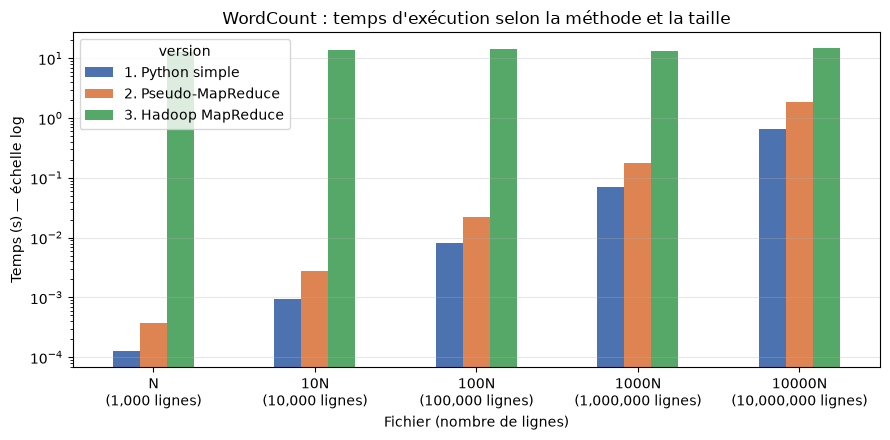

In [21]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.DataFrame(RESULTATS, columns=["version", "corpus", "temps_s"])
tab = df.pivot(index="corpus", columns="version", values="temps_s").loc[list(CORPUS)]
tab.insert(0, "lignes", [LIGNES[n] for n in tab.index])
display(tab.round(4))

ax = tab.drop(columns="lignes").plot.bar(figsize=(9, 4.5), rot=0, logy=True,
                                         color=["#4C72B0", "#DD8452", "#55A868"])
ax.set_ylabel("Temps (s) — échelle log")
ax.set_xlabel("Fichier (nombre de lignes)")
ax.set_xticklabels([f"{n}\n({LIGNES[n]:,d} lignes)" for n in tab.index])
ax.set_title("WordCount : temps d'exécution selon la méthode et la taille")
ax.grid(axis="y", alpha=.3)
plt.tight_layout(); plt.show()

Le temps pour Hadoop est quasiment constant (la majeure partie de ce temps est le lancement du job et pas du traitement de données) tandis que les versions Python et Pseudo-MapReduce augmentent significativement avec le volume.

In [22]:
# Décomposition du temps de la version 2 par phase
pd.DataFrame(PHASES_V2).set_index("corpus").round(4)

,map,shuffle,reduce,paires intermédiaires
corpus,,,,
N,0.0003,0.0001,0.0000,1000
10N,0.0024,0.0004,0.0000,10000
100N,0.0183,0.0034,0.0002,100000
1000N,0.1502,0.0290,0.0018,1000000
10000N,1.4952,0.3425,0.0195,10000000


### 4.2 Analyse

**Résultats** (mesurés sur le Mac, ils varient légèrement d'une exécution à l'autre)

| Fichier | Lignes | 1. Python simple | 2. Pseudo-MapReduce | 3. Hadoop MapReduce |
|---|---|---|---|---|
| `mots_N.txt` | 1 000 | 0,0001 s | 0,0004 s | 14,06 s |
| `mots_10N.txt` | 10 000 | 0,0011 s | 0,0106 s | 13,07 s |
| `mots_100N.txt` | 100 000 | 0,0097 s | 0,0219 s | 13,24 s |
| `mots_1000N.txt` | 1 000 000 | 0,0690 s | 0,1837 s | 14,22 s |
| `mots_10000N.txt` | 10 000 000 | 0,6636 s | 1,8457 s | 15,27 s |

Les trois méthodes donnent exactement les mêmes comptes (ex. `bouteille` : 12, 120, 1 200, 12 000, 120 000).

**Ce qu'on observe**
1. **Python simple est le plus rapide pour des petits fichiers.** Son temps est proportionnel à la taille du fichier : environ 10 fois plus de temps pour 10 fois plus de lignes, de 0,07 s sur 1000N à 0,66 s sur 10000N.
2. **Le pseudo-MapReduce est 2 à 3 fois plus lent** que Python simple. Il fait le même calcul, mais il garde en mémoire une paire `(mot, 1)` pour chaque mot, soit 10 millions de paires sur 10000N. Sur ce fichier, regrouper ces paires (`shuffle`) prend déjà environ un cinquième du temps.
3. **Hadoop met environ 13 à 14 s jusqu'à 1 million de lignes**, quelle que soit la taille. Ce temps sert presque entièrement à démarrer : Java, YARN et HDFS.
4. **À 10 millions de lignes, Hadoop commence à ralentir** (15,3 s, soit 1 à 2 s de plus). C'est la première fois que le traitement des données pèse vraiment dans son temps total.
5. **L'écart se réduit quand le volume augmente.** Les versions 1 et 2 ralentissent avec la taille, alors que Hadoop reste presque stable. Sur 1 000 lignes, Hadoop est plus de 100 000 fois plus lent que Python simple ; sur 10 millions de lignes, seulement environ 23 fois.
6. **Hadoop ne travaille toujours pas en parallèle.** Même à 61 Mo, le fichier tient dans un seul bloc HDFS (128 Mo), donc un seul mapper est lancé. Le Combiner résume quand même les 10 millions de paires en quelques totaux par mot avant de les envoyer au reducer.

Ces ordres de grandeur sont proches de ceux évoqués dans le pdf (0,012 s, 0,017 s et 12 s).

**Quand Hadoop devient-il utile ?**
Sur une seule machine et avec un seul mapper, Hadoop ne rattrapera pas Python simple : quand le fichier grossit, son temps augmente lui aussi. Il devient intéressant quand le fichier occupe **de nombreux blocs** traités **en parallèle sur plusieurs machines** (un cluster), et quand les données sont **trop grosses pour un seul ordinateur** (centaines de Go, To).

**Comparaison des trois méthodes**

| | 1. Python simple | 2. Pseudo-MapReduce | 3. Hadoop MapReduce |
|---|---|---|---|
| **Principe** | Une boucle + un dictionnaire | `mapper` → `shuffle` → `reducer` | Mêmes étapes, réparties sur des machines |
| **Outils** | Python | Python | Java, HDFS, YARN |
| **Temps sur 10000N** | 0,66 s | 1,85 s | 15,3 s |
| **Limite / atout** | Une seule machine | Une seule machine, beaucoup de mémoire | Lent à démarrer, mais passe à l'échelle et résiste aux pannes |
| **Usage** | Petits volumes | Comprendre MapReduce | Très gros volumes |

**Conclusion**
MapReduce ne rend pas un calcul plus rapide : il permet de le **répartir sur plusieurs machines**. Sur une seule machine et des fichiers de quelques dizaines de Mo, cette organisation coûte du temps. Elle devient indispensable quand les données sont trop volumineuses pour un seul ordinateur.

In [23]:
# Arrêt propre des services Hadoop (à exécuter à la fin)
for d in ["yarn --daemon stop nodemanager", "yarn --daemon stop resourcemanager",
          "hdfs --daemon stop datanode", "hdfs --daemon stop namenode"]:
    sh(d, check=False)
print(sh("jps").stdout)

14379 Jps



---

# Partie 2 — WordCount avec PySpark

## 5. Le problème et présentation de PySpark

### 5.1 Le problème

On reprend **exactement le même problème** que dans la partie 1 : compter le nombre d'occurrences de chaque mot dans les fichiers `data/mots_N.txt` à `data/mots_10000N.txt` (un mot par ligne). Le résultat attendu est connu : il doit être identique à celui de la version 1, par exemple `bouteille` = 12 sur N lignes et 120 000 sur 10 000·N lignes.

La partie 1 a montré deux limites :
- **Python simple** est rapide mais ne fonctionne que sur **une machine** et avec **un seul cœur**.
- **Hadoop MapReduce** sait répartir le travail, mais il coûte environ 13 s par job, même pour 1 000 lignes. De plus, il démarre de nouvelles machines Java à chaque job et **écrit sur disque** entre les étapes Map et Reduce.

### 5.2 Qu'est-ce que Spark et PySpark ?

**Apache Spark** est un moteur de calcul distribué créé pour dépasser les limites de Hadoop MapReduce. **PySpark** est son interface Python : on écrit du Python, et Spark (écrit en Scala, sur la machine virtuelle Java) exécute le calcul.

| Notion | Explication |
|---|---|
| **SparkSession / SparkContext** | Le point d'entrée : il pilote le calcul (le *driver*) et distribue le travail aux *executors*. |
| **RDD** (*Resilient Distributed Dataset*) | Une collection de données **découpée en partitions**, chaque partition pouvant être traitée par un cœur ou une machine différente. |
| **DataFrame** | Une table distribuée avec des colonnes nommées, comme une table SQL ou un DataFrame pandas, optimisée automatiquement par Spark. |
| **Transformation** | Une opération qui décrit un nouveau jeu de données (`map`, `flatMap`, `reduceByKey`, `groupBy`…). Rien n'est calculé tout de suite. |
| **Action** | Une opération qui demande un résultat (`collect`, `count`, `show`…). C'est elle qui **déclenche** le calcul. |
| **DAG** | Le plan d'exécution : Spark enchaîne toutes les transformations et ne fait un *shuffle* que lorsque c'est nécessaire. |
| **Cache** | Spark peut **garder des données en mémoire** pour les réutiliser sans relire le disque. |

**Différences clés avec Hadoop MapReduce**
- Les résultats intermédiaires restent **en mémoire** au lieu d'être écrits sur disque entre chaque étape.
- Les machines Java (*executors*) sont **démarrées une seule fois** pour toute la session, pas à chaque job.
- Le code est **beaucoup plus court** : quelques lignes au lieu d'un mapper et d'un reducer séparés.

Ici, Spark tourne en **mode local** (`local[*]`) : le *driver* et les *executors* sont sur le Mac, et chaque cœur (10 coeurs sur mon Mac) du processeur joue le rôle d'une machine du cluster. Le même code fonctionnerait sans changement sur un vrai cluster.

## 6. Mise en place de Spark

Config donnée par Claude pour Mac :
>PySpark s'installe comme une bibliothèque Python (`pip install "pyspark==3.5.*"`, déjà fait dans le `.venv`). La version 3.5 est choisie car elle fonctionne avec **Java 11**, déjà installé pour Hadoop dans `~/hadoop_tp`. Spark n'a pas besoin de HDFS ni de YARN en mode local : il lit directement les fichiers du dossier `data/`.

In [24]:
import os, sys, time, glob
from pathlib import Path

# PySpark 3.5 utilise Java 11 : on réutilise celui installé pour Hadoop (partie 3)
os.environ["JAVA_HOME"] = sorted(glob.glob(str(Path.home() / "hadoop_tp" / "jdk-11*")))[-1] + "/Contents/Home"
# Les processus Python lancés par Spark utilisent le même Python que le notebook
os.environ["PYSPARK_PYTHON"] = sys.executable

from pyspark.sql import SparkSession

def local(path):
    "Chemin explicite vers le disque local : sinon Spark chercherait le fichier dans HDFS (configuré en partie 3)."
    return "file://" + str(Path(path).resolve())

def demarrer_spark(master="local[*]"):
    "Démarre une session Spark. local[*] = tous les cœurs du Mac, local[1] = un seul cœur."
    session = (SparkSession.builder
               .master(master)
               .appName("WordCount")
               .config("spark.ui.showConsoleProgress", "false")
               .getOrCreate())
    session.sparkContext.setLogLevel("ERROR")
    return session

t0 = time.perf_counter()
spark = demarrer_spark()
sc = spark.sparkContext
T_DEMARRAGE_SPARK = time.perf_counter() - t0
print(f"Spark {spark.version} démarré en {T_DEMARRAGE_SPARK:.1f} s | {sc.defaultParallelism} cœurs utilisés")

Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/10/13 15:43:10 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Spark 3.5.9 démarré en 1.4 s | 10 cœurs utilisés


Les 10 coeurs sont bien détectés par Spark, et le code est exécuté en parallèle sur ces 10 coeurs.

## 7. Le code expliqué

### 7.1 Version RDD : MapReduce en quelques lignes

Les mêmes étapes que dans la partie 1 (Map → Shuffle → Reduce), écrites avec l'API RDD :

| Étape | Code Spark | Équivalent partie 1 |
|---|---|---|
| Lecture découpée en partitions | `sc.textFile(chemin, minPartitions=…)` | blocs HDFS / splits |
| **Map** : une ligne → ses mots | `flatMap(lambda ligne: ligne.split())` | `mapper` (découpage) |
| **Map** : un mot → `(mot, 1)` | `map(lambda mot: (mot, 1))` | `mapper` (paires) |
| **Shuffle + Reduce** : somme par mot | `reduceByKey(add)` | `shuffle` + `reducer` (+ Combiner) |
| Récupération du résultat | `collect()` | `hdfs dfs -cat part-r-00000` |

`reduceByKey` additionne d'abord les paires **à l'intérieur de chaque partition** (comme le Combiner de Hadoop), puis seulement les totaux partiels sont échangés entre partitions.

In [25]:
from operator import add

def wordcount_rdd(path, partitions=None):
    "WordCount avec l'API RDD de Spark."
    partitions = partitions or sc.defaultParallelism              # par défaut : une partition par cœur
    lignes  = sc.textFile(local(path), minPartitions=partitions)
    mots    = lignes.flatMap(lambda ligne: ligne.split())        # Map : ligne -> mots
    paires  = mots.map(lambda mot: (mot, 1))                     # Map : mot -> (mot, 1)
    comptes = paires.reduceByKey(add)                            # Shuffle + Reduce : somme par mot
    return dict(comptes.collect())                               # Action : déclenche le calcul

**Évaluation paresseuse** : tant qu'on n'appelle pas d'action, Spark ne fait que construire le plan. Dans la cellule suivante, la création de `comptes` ne lit aucune donnée : Spark prépare seulement le plan. Le calcul n'a lieu qu'au `take`. `toDebugString()` affiche le plan (le DAG) : on y voit le *shuffle* introduit par `reduceByKey`.

In [26]:
t0 = time.perf_counter()
lignes  = sc.textFile(local(CORPUS["N"]))
comptes = lignes.flatMap(lambda l: l.split()).map(lambda m: (m, 1)).reduceByKey(add)
print(f"Construction du plan : {(time.perf_counter() - t0) * 1000:.1f} ms (aucun calcul)")
print(comptes.toDebugString().decode())

t0 = time.perf_counter()
print("\n5 premiers résultats :", comptes.take(5))
print(f"Action take(5) : {time.perf_counter() - t0:.2f} s (le calcul a lieu ici)")

Construction du plan : 611.1 ms (aucun calcul)
(2) PythonRDD[6] at RDD at PythonRDD.scala:53 []
 |  MapPartitionsRDD[5] at mapPartitions at PythonRDD.scala:160 []
 |  ShuffledRDD[4] at partitionBy at NativeMethodAccessorImpl.java:0 []
 +-(2) PairwiseRDD[3] at reduceByKey at /var/folders/1s/4qln7b850mj8d7n6b338c6dw0000gn/T/ipykernel_2629/960629351.py:3 []
    |  PythonRDD[2] at reduceByKey at /var/folders/1s/4qln7b850mj8d7n6b338c6dw0000gn/T/ipykernel_2629/960629351.py:3 []
    |  file:///Users/batistaureille/Desktop/Big Data/data/mots_N.txt MapPartitionsRDD[1] at textFile at NativeMethodAccessorImpl.java:0 []
    |  file:///Users/batistaureille/Desktop/Big Data/data/mots_N.txt HadoopRDD[0] at textFile at NativeMethodAccessorImpl.java:0 []

5 premiers résultats : [('route', 40), ('soleil', 60), ('eau', 35), ('pain', 20), ('oiseau', 30)]
Action take(5) : 0.56 s (le calcul a lieu ici)


### 7.2 Version DataFrame : le même calcul, en style SQL

Avec l'API DataFrame, on décrit **ce qu'on veut** et Spark choisit **comment le faire** (optimiseur *Catalyst*). Le calcul est exécuté directement dans la machine Java, sans passer par des fonctions Python : c'est en général plus rapide que les RDD avec des `lambda`.

| Étape | Code |
|---|---|
| Lecture : une ligne du fichier = une ligne de la table (colonne `value`) | `spark.read.text(chemin)` |
| Découpage en mots, un mot par ligne de la table | `explode(split(trim(value), "\s+"))` |
| Comptage par mot | `groupBy("mot").count()` |

C'est l'équivalent de la requête SQL `SELECT mot, COUNT(*) FROM mots GROUP BY mot`.

In [27]:
from pyspark.sql import functions as F

def wordcount_dataframe(path):
    "WordCount avec l'API DataFrame de Spark."
    df      = spark.read.text(local(path))                     # colonne "value" = une ligne
    mots    = (df.select(F.explode(F.split(F.trim("value"), r"\s+")).alias("mot"))
                 .where(F.col("mot") != ""))                                 # une ligne par mot
    comptes = mots.groupBy("mot").count()                                    # comptage par mot
    return {r["mot"]: r["count"] for r in comptes.collect()}

# Aperçu sur le fichier de N lignes, trié par nombre d'occurrences
(spark.read.text(local(CORPUS["N"]))
      .select(F.explode(F.split(F.trim("value"), r"\s+")).alias("mot"))
      .where(F.col("mot") != "")
      .groupBy("mot").count()
      .orderBy(F.desc("count"))
      .show(10))

+--------+-----+
|     mot|count|
+--------+-----+
|    chat|  120|
|   chien|  100|
|   arbre|   80|
|   fleur|   80|
|  maison|   70|
|montagne|   60|
|  soleil|   60|
|   livre|   50|
|    ciel|   50|
|    lune|   40|
+--------+-----+
only showing top 10 rows



## 8. Tests

1. **Test unitaire** sur un petit exemple dont on connaît la réponse.
2. **Mêmes résultats que la version 1** (Python simple) sur les 5 fichiers, pour les deux versions Spark.

In [28]:
# Test 1 : petit exemple connu
exemple = ["chat chien", "chat", "bouteille chat"]
resultat = dict(sc.parallelize(exemple).flatMap(str.split).map(lambda m: (m, 1)).reduceByKey(add).collect())
assert resultat == {"chat": 3, "chien": 1, "bouteille": 1}, resultat
print("✅ Test 1 : petit exemple correct ->", resultat)

# Test 2 : résultats identiques à la version 1 sur tous les fichiers
for nom, path in CORPUS.items():
    assert wordcount_rdd(path) == res_v1[nom], f"RDD différent sur {nom}"
    assert wordcount_dataframe(path) == res_v1[nom], f"DataFrame différent sur {nom}"
print("✅ Test 2 : RDD et DataFrame identiques à la version 1 sur", list(CORPUS))
print("   bouteille :", {nom: wordcount_rdd(p)["bouteille"] for nom, p in CORPUS.items()})

✅ Test 1 : petit exemple correct -> {'chat': 3, 'chien': 1, 'bouteille': 1}
✅ Test 2 : RDD et DataFrame identiques à la version 1 sur ['N', '10N', '100N', '1000N', '10000N']
   bouteille : {'N': 12, '10N': 120, '100N': 1200, '1000N': 12000, '10000N': 120000}


On remarque que, pour "bouteille", le compte est bien 12 sur `mots_N.txt` et 120 000 sur `mots_10000N.txt`, comme dans la partie 1 --> résultats corrects et cohérents avec les attendus.

## 9. Mesures

### 9.1 Temps d'exécution sur les 5 fichiers

On mesure le temps de chaque calcul **une fois la session Spark démarrée**, puisque le démarrage n'a lieu qu'une fois (son temps est affiché à part). Les tests précédents ont déjà « chauffé » Spark, comme une session réelle où l'on enchaîne plusieurs calculs. Chaque mesure est la moyenne de 3 essais.

In [29]:
REPETITIONS = 3
RESULTATS_SPARK = []
for nom, path in CORPUS.items():
    for version, fonction in [("4. PySpark RDD", wordcount_rdd), ("5. PySpark DataFrame", wordcount_dataframe)]:
        temps = []
        for _ in range(REPETITIONS):
            t0 = time.perf_counter()
            fonction(path)
            temps.append(time.perf_counter() - t0)
        RESULTATS_SPARK.append((version, nom, sum(temps) / len(temps)))
    print(f"{nom:6s} : RDD {RESULTATS_SPARK[-2][2]:6.3f} s | DataFrame {RESULTATS_SPARK[-1][2]:6.3f} s")
print(f"\n(+ démarrage de la session Spark, une seule fois : {T_DEMARRAGE_SPARK:.1f} s)")

N      : RDD  0.097 s | DataFrame  0.052 s
10N    : RDD  0.109 s | DataFrame  0.055 s
100N   : RDD  0.106 s | DataFrame  0.064 s
1000N  : RDD  0.204 s | DataFrame  0.176 s
10000N : RDD  1.070 s | DataFrame  0.429 s

(+ démarrage de la session Spark, une seule fois : 1.4 s)


### 9.2 Parallélisme : 1 cœur contre tous les cœurs

Avec Hadoop, utiliser plusieurs mappers demande de reconfigurer le découpage du fichier. Avec Spark, changer le nombre de cœurs ne demande qu'un paramètre : `local[1]` (1 cœur) ou `local[*]` (tous les cœurs). On compare les deux sur `mots_10000N.txt`, avec la version RDD.

In [30]:
PARALLELISME_SPARK = []
for master in ["local[1]", "local[*]"]:
    spark.stop()                                   # on relance Spark avec un autre nombre de cœurs
    spark = demarrer_spark(master)
    sc = spark.sparkContext
    wordcount_rdd(CORPUS["N"])                     # premier calcul pour « chauffer » la session
    temps = []
    for _ in range(REPETITIONS):
        t0 = time.perf_counter()
        res = wordcount_rdd(CORPUS["10000N"])
        temps.append(time.perf_counter() - t0)
    assert res == res_v1["10000N"]
    PARALLELISME_SPARK.append({"master": master, "cœurs": sc.defaultParallelism,
                               "partitions": sc.defaultParallelism, "temps_moyen_s": sum(temps) / len(temps)})
    print(f"{master:9s} : {sc.defaultParallelism:2d} cœur(s) | {PARALLELISME_SPARK[-1]['temps_moyen_s']:.2f} s")

gain = PARALLELISME_SPARK[0]["temps_moyen_s"] / PARALLELISME_SPARK[1]["temps_moyen_s"]
print(f"\nAccélération avec tous les cœurs : x{gain:.1f}")

local[1]  :  1 cœur(s) | 4.45 s
local[*]  : 10 cœur(s) | 1.06 s

Accélération avec tous les cœurs : x4.2


### 9.3 Le cache en mémoire

C'est l'apport principal de Spark par rapport à Hadoop : on peut **garder les données en mémoire** entre deux calculs. Hadoop, lui, relit le fichier sur disque à chaque job.

On lit `mots_10000N.txt`, on le met en cache (`cache()`), puis on enchaîne deux calculs différents sur les mêmes données.

In [31]:
mots_10000N = (sc.textFile(local(CORPUS["10000N"]), minPartitions=sc.defaultParallelism)
                 .flatMap(lambda l: l.split()))
mots_10000N.cache()                                     # demande à Spark de garder les données en mémoire

CACHE = []
for i, (calcul, action) in enumerate([
        ("Nombre total de mots",       lambda: mots_10000N.count()),
        ("Nombre total de mots",       lambda: mots_10000N.count()),
        ("WordCount complet",          lambda: dict(mots_10000N.map(lambda m: (m, 1)).reduceByKey(add).collect())),
        ("Mots de plus de 5 lettres",  lambda: mots_10000N.filter(lambda m: len(m) > 5).count())]):
    t0 = time.perf_counter()
    r = action()
    dt = time.perf_counter() - t0
    source = "lecture du disque + mise en cache" if i == 0 else "données en mémoire"
    CACHE.append({"calcul": calcul, "source": source, "temps_s": dt})
    print(f"{calcul:26s} ({source:34s}) : {dt:5.2f} s")

mots_10000N.unpersist()                                 # libère la mémoire

Nombre total de mots       (lecture du disque + mise en cache ) :  0.85 s
Nombre total de mots       (données en mémoire                ) :  0.11 s
WordCount complet          (données en mémoire                ) :  0.49 s
Mots de plus de 5 lettres  (données en mémoire                ) :  0.20 s


PythonRDD[30] at RDD at PythonRDD.scala:53

## 10. Comparaison avec la partie 1

version,lignes,1. Python simple,2. Pseudo-MapReduce,3. Hadoop MapReduce,4. PySpark RDD,5. PySpark DataFrame
corpus,,,,,,
N,1000,0.0001,0.0004,12.9578,0.0967,0.0519
10N,10000,0.0009,0.0028,13.6442,0.1094,0.0546
100N,100000,0.0081,0.0219,14.1793,0.1062,0.0636
1000N,1000000,0.0703,0.1810,13.2066,0.2041,0.1758
10000N,10000000,0.6550,1.8572,15.1952,1.0702,0.4292


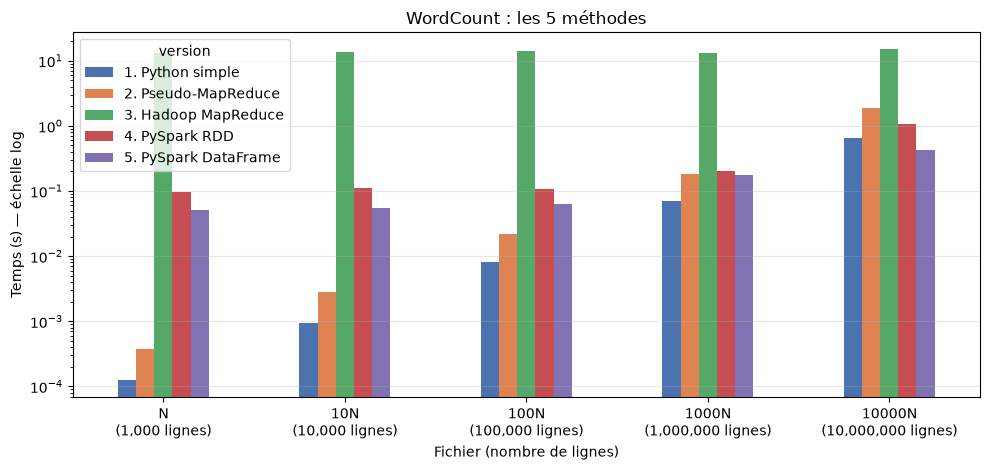

In [32]:
import pandas as pd
import matplotlib.pyplot as plt

df_all = pd.DataFrame(RESULTATS + RESULTATS_SPARK, columns=["version", "corpus", "temps_s"])
tab_all = df_all.pivot_table(index="corpus", columns="version", values="temps_s").loc[list(CORPUS)]
tab_all.insert(0, "lignes", [LIGNES[n] for n in tab_all.index])
display(tab_all.round(4))

ax = tab_all.drop(columns="lignes").plot.bar(figsize=(10, 4.8), rot=0, logy=True,
                                             color=["#4C72B0", "#DD8452", "#55A868", "#C44E52", "#8172B3"])
ax.set_ylabel("Temps (s) — échelle log")
ax.set_xlabel("Fichier (nombre de lignes)")
ax.set_xticklabels([f"{n}\n({LIGNES[n]:,d} lignes)" for n in tab_all.index])
ax.set_title("WordCount : les 5 méthodes")
ax.grid(axis="y", alpha=.3)
plt.tight_layout(); plt.show()

## 11. Conclusion : ce qu'apporte PySpark

**Résultats** (mesurés sur le Mac ; ils varient légèrement d'une exécution à l'autre)

| Fichier | Lignes | 1. Python simple | 2. Pseudo-MapReduce | 3. Hadoop MapReduce | 4. PySpark RDD | 5. PySpark DataFrame |
|---|---|---|---|---|---|---|
| `mots_N.txt` | 1 000 | 0,0001 s | 0,0004 s | 14,1 s | 0,096 s | 0,054 s |
| `mots_10N.txt` | 10 000 | 0,0011 s | 0,0106 s | 13,1 s | 0,102 s | 0,049 s |
| `mots_100N.txt` | 100 000 | 0,0097 s | 0,0219 s | 13,2 s | 0,107 s | 0,063 s |
| `mots_1000N.txt` | 1 000 000 | 0,0690 s | 0,1837 s | 14,2 s | 0,193 s | 0,172 s |
| `mots_10000N.txt` | 10 000 000 | 0,664 s | 1,846 s | 15,3 s | 1,053 s | **0,410 s** |

La session Spark démarre **une seule fois**, en 1,5 s, puis on enchaîne tous les calculs.

Les cinq méthodes donnent exactement les mêmes comptes (exemple `bouteille` : 12, 120, 1 200, 12 000, 120 000).

**Ce qu'on observe**
1. **Spark est beaucoup plus rapide que Hadoop** : 0,05 à 1,05 s par calcul, contre 13 à 15 s. Sur 10000N, la version DataFrame va environ **37 fois plus vite** que Hadoop MapReduce. Hadoop redémarre des machines Java et écrit sur disque à chaque job, alors que Spark garde sa session ouverte et ses données en mémoire.
2. **Sur les petits fichiers, Python simple reste le plus rapide.** Spark a un petit coût par calcul (environ 0,05 à 0,1 s pour organiser les tâches), qui ne vaut pas la peine pour 1 000 lignes.
3. **Sur le plus gros fichier, la version DataFrame bat même Python simple** (0,41 s contre 0,66 s), car elle utilise les 10 cœurs du Mac. C'est la seule méthode du TP qui devient plus rapide que Python simple pour cette volumétrie de fichiers.
4. **DataFrame est environ 2,5 fois plus rapide que RDD** sur 10000N. Avec les RDD, chaque mot passe par une fonction Python (`lambda`). Avec les DataFrame, tout le calcul reste dans la machine Java et il est optimisé automatiquement par Spark.
5. **Le parallélisme est impactant** : passer de 1 cœur (`local[1]`, 4,5 s) à tous les cœurs (`local[*]`, 1,1 s) divise le temps par **4,2**. Il suffit pour cela de changer un seul paramètre, sans reconfigurer le découpage comme avec Hadoop.
6. **Le cache en mémoire évite de relire le disque** : le premier comptage sur 10000N prend 0,86 s (lecture + mise en cache), le suivant 0,13 s, soit **près de 7 fois moins**. Les calculs suivants (WordCount complet, filtre) réutilisent aussi les données déjà en mémoire.

**Comparaison des méthodes**

| | Python simple | Hadoop MapReduce | PySpark |
|---|---|---|---|
| **Code** | 10 lignes | Mapper + reducer + configuration (lourd) | 5 lignes (RDD) ou une requête type SQL (DataFrame) |
| **Données intermédiaires** | En mémoire, une seule machine | Écrites sur disque entre Map et Reduce | En mémoire, réparties entre les cœurs ou les machines |
| **Coût de démarrage** | Aucun | ~13 s **à chaque job** | ~1,5 s **une seule fois** par session |
| **Parallélisme** | Aucun (1 cœur) | Selon le nombre de blocs HDFS | Modulable : on peut utilisertous les cœurs, en modifiant un seul paramètre |
| **Passage à un cluster** | Impossible | Oui | Oui, avec le même code |
| **Usage interactif** | Oui | Non (jobs par lots) | Oui (notebook) |
| **Temps sur 10000N** | 0,66 s | 15,3 s | 0,41 s (DataFrame) |

**Ce qu'apporte PySpark**
- **La rapidité de Python simple et la puissance de Hadoop** : sur une machine, il est proche de Python simple, et même plus rapide sur les gros fichiers. Il passe aussi à l'échelle sur un cluster, comme Hadoop.
- **Le calcul en mémoire**, qui supprime les écritures disque entre les étapes, principal défaut de Hadoop MapReduce. C'est décisif pour les traitements qui enchaînent plusieurs étapes ou relisent les mêmes données (cache).
- **Un code simple et lisible**, en Python, qui reprend exactement le modèle MapReduce (`flatMap` → `map` → `reduceByKey`), ou qui s'écrit comme une requête SQL avec les DataFrame.
- **Un parallélisme immédiat**, sur tous les cœurs ou toutes les machines, sans changer le code.

**Limite** : pour de petits fichiers sur une seule machine, Python simple reste plus rapide et plus simple. Spark devient intéressant dès que les données sont volumineuses, que les calculs s'enchaînent, ou qu'il faut passer sur un cluster. C'est pour ces raisons qu'il a largement remplacé Hadoop MapReduce dans les traitements Big Data actuels.

In [33]:
# Arrêt de Spark (à exécuter à la fin)
spark.stop()
print("Session Spark arrêtée")

Session Spark arrêtée
